<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Spinwave_Dispersion_AFM_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

100%|██████████| 201/201 [00:09<00:00, 21.10it/s]


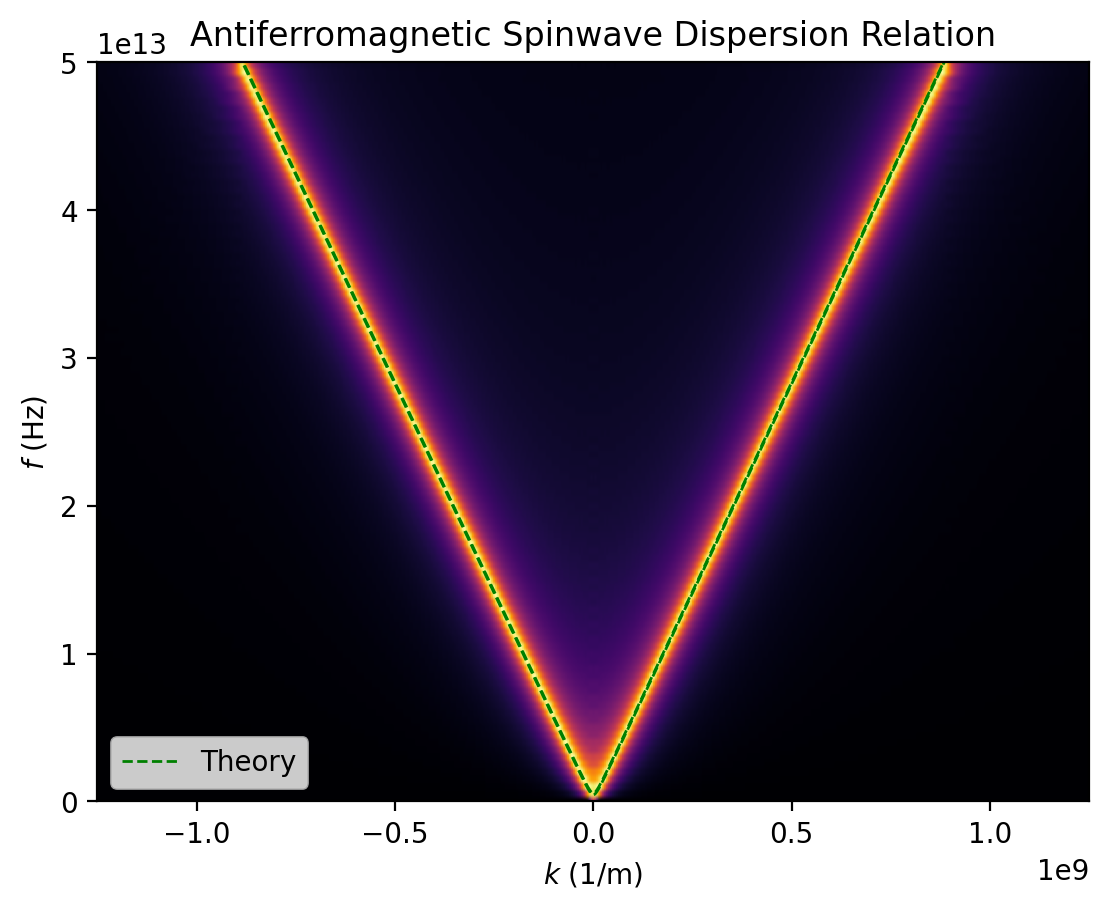

In [3]:
import os.path

import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

from mumaxplus import Antiferromagnet, Grid, World
from mumaxplus.util.constants import GAMMALL_DEFAULT

plt.rcParams["figure.dpi"] = 200

# Antiferromagnetic spinwave dispersion relation

# Numerical parameters
fmax = 5E13            # maximum frequency (in Hz) of the sinc pulse
T = 2E-12              # simulation time (longer -> better frequency resolution)
dt = 1 / (2 * fmax)    # the sample time
nt = 1 + int(T / dt)
dx = 0.5E-9            # cellsize
nx = 512*5             # number of cells

# Material/system parameters
a = 0.35e-9              # lattice constant
Bz = 2             # bias field along the z direction
A = 10E-12          # exchange constant
A_nn = -5E-12
A_c = -400E-12
Ms = 400e3          # saturation magnetization
alpha = 1e-3        # damping parameter
K = 1e3

# Create the world
grid_size = (nx, 1, 1)
cell_size = (dx, dx, dx)

m_filename = "AFM_disp.npy"

world = World(cell_size)
world.bias_magnetic_field = (0, 0, Bz)

def simulate():
    # Create a ferromagnet
    magnet = Antiferromagnet(world, Grid(size=grid_size))
    magnet.msat = Ms
    magnet.aex = A
    magnet.alpha = alpha
    magnet.ku1 = K
    magnet.anisU = (0, 0, 1)

    magnet.afmex_nn = A_nn
    magnet.afmex_cell = A_c
    magnet.latcon = a

    Bt = lambda t: (1e2 * np.sinc(2 * fmax * (t - T / 2)), 0, 0)
    mask = np.zeros(shape=(1, 1, nx))
    # Put signal at the center of the simulation box
    mask[:, :, nx // 2 - 1:nx // 2 + 1] = 1
    for sub in magnet.sublattices:
        sub.bias_magnetic_field.add_time_term(Bt, mask)

    magnet.sub1.magnetization = (0, 0, 1)
    magnet.sub2.magnetization = (0, 0, -1)

    # Run solver
    m = np.zeros(shape=(nt, 3, 1, 1, nx))
    m[0,...] = magnet.sub1.magnetization.eval()
    for i in tqdm(range(nt)):
        world.timesolver.run(dt)
        m[i,...] = magnet.sub1.magnetization.eval()
    np.save(m_filename, m)
    return m

# check if the files already exist
if os.path.isfile(m_filename):
    m = np.load(m_filename)
else:
    m = simulate()

# x- and y-coordinates of FT cell centers
ks = np.fft.fftshift(np.fft.fftfreq(nx, dx) * 2*np.pi)
fs = np.fft.fftshift(np.fft.fftfreq(nt, dt))
# FT cell widths
dk = ks[1] - ks[0]
df = fs[1] - fs[0]
# image extent of k-values and frequencies, compensated for cell-width
extent = [ks[0] - dk/2, ks[-1] + dk/2, fs[0] - df/2, fs[-1] + df/2]

# Fourier transform in time and x-direction of magnetization
m_FT = np.abs(np.fft.fftshift(np.fft.fft2(m[:,1,0,0,:])))

# extent of k values and frequencies, compensated for cell-width
xmin, xmax = -1.25*1e9, 1.25*1e9  # rad/m
ymin, ymax = 0, fmax  # Hz

# normalize the transform in the relevant area, so it is visible in the plot
x_start = int((xmin - extent[0]) / (extent[1] - extent[0]) * nx)
x_end = int((xmax - extent[0]) / (extent[1] - extent[0]) * nx)
y_start = int((ymin - extent[2]) / (extent[3] - extent[2]) * nt)
y_end = int((ymax - extent[2]) / (extent[3] - extent[2]) * nt)

m_max = np.max(m_FT[y_start:y_end, x_start:x_end])

FT_tot = m_FT/m_max

fig, ax = plt.subplots()
linewidth = 2

# Plot the analytical derived dispersion relation
k = np.linspace(xmin, xmax, 2500)
wext = Bz
wani = 2 * K / Ms
wex = 2*A/Ms * k**2
wc = 4*A_c/(a*a*Ms)
wnn = A_nn/Ms * k**2
wmagnon = np.sqrt((wani + wex - wnn) * (wani + wex - 2*wc + wnn))
w1 = GAMMALL_DEFAULT * (wmagnon + wext)
w2 = GAMMALL_DEFAULT * (wmagnon - wext)
w3 = GAMMALL_DEFAULT * (-wmagnon + wext)
w4 = GAMMALL_DEFAULT * (-wmagnon - wext)

ax.plot(k, w1/(2*np.pi), '--', lw=1, color="green", label="Theory")
ax.plot(k, w2/(2*np.pi), '--', lw=1, color="green")
ax.plot(k, w3/(2*np.pi), '--', lw=1, color="green")
ax.plot(k, w4/(2*np.pi), '--', lw=1, color="green")

# plot numerical result
ax.imshow(FT_tot, aspect='auto', origin='lower', extent=extent, cmap="inferno")

# Shows how much the dispersion relation has shifted up due to an external field
ax.axhline(GAMMALL_DEFAULT * Bz / (2 * np.pi), c='g', ls='--', lw=1)

# Shows where mumax⁺ breaks down due to waves being smaller than cell size
ax.vlines([-1/dx, 1/dx], 0, fmax, 'r', '--', lw=1)

ax.set_xlim([xmin, xmax])
ax.set_ylim([ymin, ymax])
ax.set_ylabel("$f$ (Hz)")
ax.set_xlabel("$k$ (1/m)")
ax.set_title('Antiferromagnetic Spinwave Dispersion Relation')
plt.legend()
plt.show()